# 02 Data Quality Analysis

This notebook inspects the messy synthetic copy and the defect manifest before any correction is applied.


In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

def find_project_root(start: Path | None = None) -> Path:
    current = (start or Path.cwd()).resolve()
    for path in [current, *current.parents]:
        if (path / "src").exists() and (path / "data").exists():
            return path
    raise RuntimeError("Run this notebook from inside the EcomPolice project.")

PROJECT_ROOT = find_project_root()
SRC_DIR = PROJECT_ROOT / "src"
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

CLEAN_DIR = PROJECT_ROOT / "data" / "synthetic" / "clean"
MESSY_DIR = PROJECT_ROOT / "data" / "synthetic" / "messy"
LABELS_DIR = PROJECT_ROOT / "data" / "synthetic" / "labels"
MANIFESTS_DIR = PROJECT_ROOT / "data" / "synthetic" / "manifests"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_DIR = PROJECT_ROOT / "reports"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

def load_tables(base_dir: Path) -> dict[str, pd.DataFrame]:
    return {
        "customers": pd.read_csv(base_dir / "customers.csv"),
        "products": pd.read_csv(base_dir / "products.csv"),
        "orders": pd.read_csv(base_dir / "orders.csv"),
        "deliveries": pd.read_csv(base_dir / "deliveries.csv"),
        "returns": pd.read_csv(base_dir / "returns.csv"),
    }

messy_tables = load_tables(MESSY_DIR)
manifest = pd.read_csv(MANIFESTS_DIR / 'defect_manifest.csv')


In [2]:
for name, df in messy_tables.items():
    missing = df.isna().sum().rename('missing_count').to_frame()
    missing['missing_pct'] = (missing['missing_count'] / len(df) * 100).round(2)
    print(f'\n{name}')
    display(missing[missing['missing_count'] > 0].sort_values('missing_count', ascending=False))



customers


,missing_count,missing_pct



products


,missing_count,missing_pct



orders


,missing_count,missing_pct
Shipping_Method,31,0.15
Discount_Pct,28,0.14
Payment_Method,21,0.10
Customer_ID,20,0.10
Product_ID,20,0.10



deliveries


,missing_count,missing_pct
Delivery_Date,91,0.46



returns


,missing_count,missing_pct
Return_Date,16534,82.67
Return_Reason,16534,82.67
Refund_Amount_INR,16534,82.67


In [3]:
duplicate_summary = pd.DataFrame([{'table': name, 'exact_duplicate_rows': int(df.duplicated().sum())} for name, df in messy_tables.items()])
display(duplicate_summary)


,table,exact_duplicate_rows
0,customers,0
1,products,0
2,orders,58
3,deliveries,0
4,returns,0


In [4]:
orders = messy_tables['orders'].copy()
for col in ['Order_Date']:
    parsed = pd.to_datetime(orders[col], errors='coerce')
    dayfirst = pd.to_datetime(orders.loc[parsed.isna(), col], errors='coerce', dayfirst=True)
    print(col, 'initial failures:', int(parsed.isna().sum()), 'recoverable day-first:', int(dayfirst.notna().sum()))


Order_Date initial failures: 302 recoverable day-first: 302


In [5]:
numeric_cols = ['Quantity', 'Unit_Price_INR', 'Discount_Pct', 'Order_Value_INR']
converted = orders[numeric_cols].apply(lambda s: pd.to_numeric(s.astype(str).str.replace('INR', '', regex=False).str.strip(), errors='coerce'))
display(converted.describe())
display(converted[(converted[['Quantity','Unit_Price_INR']] <= 0).any(axis=1)].head())


,Quantity,Unit_Price_INR,Discount_Pct,Order_Value_INR
count,20060.000000,20060.000000,20032.000000,20060.000000
mean,1.558026,11149.284226,8.414054,14395.942941
std,4.386844,18431.107217,6.236602,26457.451364
min,-4.000000,-89999.000000,0.000000,402.410000
25%,1.000000,1936.780000,3.290000,2190.152500
50%,1.000000,4323.150000,7.940000,4999.000000
75%,2.000000,11215.280000,12.660000,13237.292500
max,196.000000,778566.250000,35.000000,359996.000000


,Quantity,Unit_Price_INR,Discount_Pct,Order_Value_INR
288,1.0,-3154.41,0.00,3154.41
783,1.0,-6329.06,6.05,5946.15
940,-1.0,2448.95,4.22,2345.60
1254,1.0,-6999.00,6.13,6569.96
1487,1.0,-47609.89,12.56,41630.09


In [6]:
category_variants = {
    'Payment_Method': sorted(orders['Payment_Method'].dropna().astype(str).unique()),
    'Shipping_Method': sorted(orders['Shipping_Method'].dropna().astype(str).unique()),
}
display(category_variants)


{'Payment_Method': ['Cash on Delivery',
  'Credit Card',
  'Debit Card',
  'Net Banking',
  'UPI',
  'Wallet',
  'cash on delivery',
  'credit card',
  'debit card',
  'net banking',
  'upi',
  'wallet'],
 'Shipping_Method': ['Express',
  'Same-Day',
  'Standard',
  'express',
  'same day',
  'standard']}

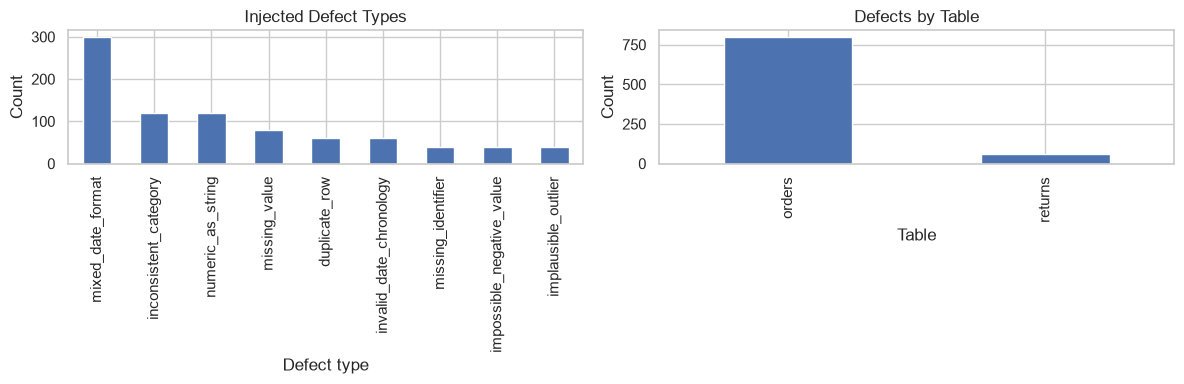

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
manifest['Defect_Type'].value_counts().plot(kind='bar', ax=axes[0], title='Injected Defect Types')
axes[0].set_xlabel('Defect type')
axes[0].set_ylabel('Count')
manifest['Table'].value_counts().plot(kind='bar', ax=axes[1], title='Defects by Table')
axes[1].set_xlabel('Table')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()


In [8]:
clean_orders = pd.read_csv(CLEAN_DIR / 'orders.csv')
broken_customers = ~orders['Customer_ID'].isin(pd.read_csv(CLEAN_DIR / 'customers.csv')['Customer_ID'])
broken_products = ~orders['Product_ID'].isin(pd.read_csv(CLEAN_DIR / 'products.csv')['Product_ID'])
quality_findings = pd.Series({
    'messy_order_rows': len(orders),
    'clean_order_rows': len(clean_orders),
    'broken_customer_references': int(broken_customers.sum()),
    'broken_product_references': int(broken_products.sum()),
    'manifest_rows': len(manifest),
})
display(quality_findings)


messy_order_rows              20060
clean_order_rows              20000
broken_customer_references       20
broken_product_references        20
manifest_rows                   860
dtype: int64

## Assessment

Exact duplicate rows can be removed. Unambiguous spelling/case variations can be standardized. Missing return dates for non-returned orders are structural and should not be treated as defects. Invalid identifiers, impossible negative values, chronology failures, and extreme outliers should be flagged or excluded from model-ready tables unless the original value can be recovered from a trusted source.
